# Wine Dataset Analysis and Decision Tree Classification

This notebook follows the steps to load, analyze, and classify the Wine dataset using a Decision Tree.

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
from sklearn.datasets import load_wine
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# Ensure plots appear inline in Jupyter
%matplotlib inline

## 1 & 2: Load and Describe Dataset

Load the Wine dataset using scikit-learn's built-in function and examine its description.

In [2]:
# Load the Wine dataset from sklearn
wine = load_wine()
X = wine.data
y = wine.target
feature_names = wine.feature_names
target_names = wine.target_names

print("--- Dataset Description ---")
print(wine.DESCR) # Print the description included with the dataset

--- Dataset Description ---
.. _wine_dataset:

Wine recognition dataset
------------------------

**Data Set Characteristics:**

:Number of Instances: 178
:Number of Attributes: 13 numeric, predictive attributes and the class
:Attribute Information:
    - Alcohol
    - Malic acid
    - Ash
    - Alcalinity of ash
    - Magnesium
    - Total phenols
    - Flavanoids
    - Nonflavanoid phenols
    - Proanthocyanins
    - Color intensity
    - Hue
    - OD280/OD315 of diluted wines
    - Proline
    - class:
        - class_0
        - class_1
        - class_2

:Summary Statistics:

============================= ==== ===== ======= =====
                                Min   Max   Mean     SD
============================= ==== ===== ======= =====
Alcohol:                      11.0  14.8    13.0   0.8
Malic Acid:                   0.74  5.80    2.34  1.12
Ash:                          1.36  3.23    2.36  0.27
Alcalinity of Ash:            10.6  30.0    19.5   3.3
Magnesium:                

### Dataset Analysis

Answer basic questions about the loaded data:

In [3]:
# 2. Answer questions based on X and y:
print("\n--- Dataset Analysis ---")

# How many records?
num_records = X.shape[0]
print(f"Number of records (samples): {num_records}")

# Are there missing values?
# Convert to pandas DataFrame for easier missing value check
df = pd.DataFrame(X, columns=feature_names)
missing_values = df.isnull().sum().sum() # Sum of nulls across all columns
print(f"Total missing values in features (X): {missing_values}")
# Also check target array y (though less common to have missing targets here)
missing_values_y = np.isnan(y).sum()
print(f"Total missing values in target (y): {missing_values_y}")
if missing_values == 0 and missing_values_y == 0:
    print("Conclusion: There are no missing values in the dataset.")
else:
    print("Conclusion: There are missing values in the dataset.")


# How many elements does each class contain?
class_counts = np.bincount(y)
print("\nNumber of elements per class:")
for i, count in enumerate(class_counts):
    print(f"  Class '{target_names[i]}' (label {i}): {count} samples")


--- Dataset Analysis ---
Number of records (samples): 178
Total missing values in features (X): 0
Total missing values in target (y): 0
Conclusion: There are no missing values in the dataset.

Number of elements per class:
  Class 'class_0' (label 0): 59 samples
  Class 'class_1' (label 1): 71 samples
  Class 'class_2' (label 2): 48 samples


## 3: Train Decision Tree Classifier (Default Config)

Create a `DecisionTreeClassifier` with default parameters and train it on the entire dataset.

In [4]:
print("\n--- Training Decision Tree (Default Config) ---")
# Create a DecisionTreeClassifier object with default configuration
dt_classifier_default = DecisionTreeClassifier(random_state=42) # Added random_state for reproducibility

# Train the classifier using the entire dataset X and y
dt_classifier_default.fit(X, y)
print("Default Decision Tree Classifier trained successfully on the entire dataset.")


--- Training Decision Tree (Default Config) ---
Default Decision Tree Classifier trained successfully on the entire dataset.


## 4: Visualize the Tree

Use `plot_tree` to visualize the structure of the trained Decision Tree.


--- Visualizing the Decision Tree ---
Generating plot...


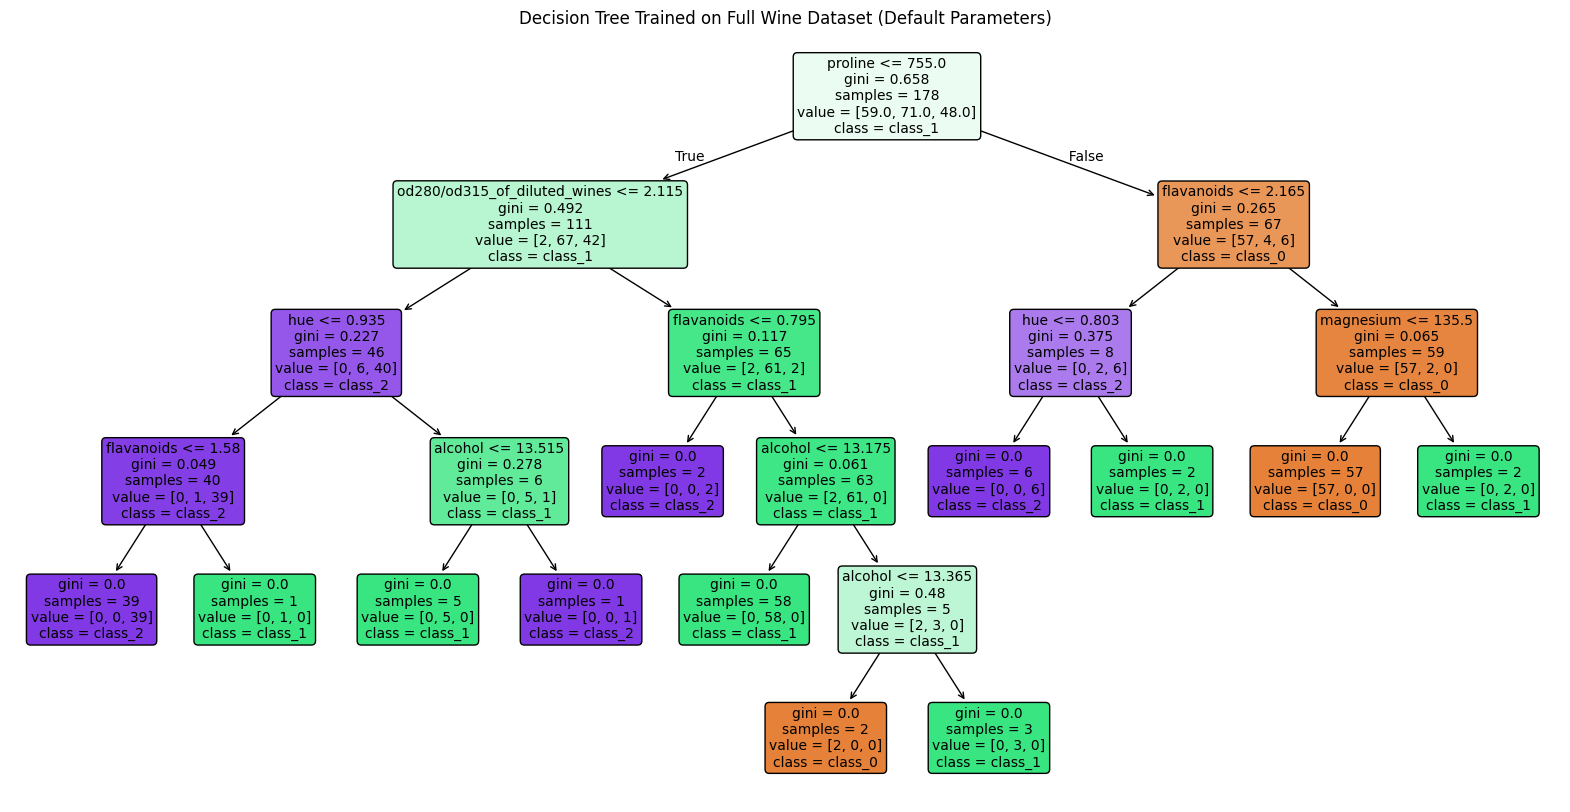

In [5]:
print("\n--- Visualizing the Decision Tree ---")
print("Generating plot...")

plt.figure(figsize=(20,10)) # Adjust figure size for better readability
plot_tree(dt_classifier_default,
          filled=True, # Color nodes based on majority class
          feature_names=feature_names, # Show feature names
          class_names=target_names, # Show class names
          rounded=True, # Use rounded corners for nodes
          fontsize=10) # Adjust font size
plt.title("Decision Tree Trained on Full Wine Dataset (Default Parameters)")
plt.show() # Display the plot

### Node Information

Each node in the decision tree plot contains the following information (typically):

1.  **Splitting Condition**: The feature and threshold used to split the data at that node (not present in leaf nodes). E.g., `'Proline <= 755.0'`.
2.  **Impurity Measure (e.g., Gini)**: The Gini impurity of the node. Gini impurity measures the likelihood of an incorrect classification if a sample was randomly classified according to the distribution of classes in the node. A Gini of 0 means all samples in the node belong to a single class (a pure node).
3.  **Samples**: The total number of training samples that reach that node.
4.  **Value**: An array showing the distribution of samples across each class (in the order specified by `class_names`) that reach the node. E.g., `[59, 71, 48]` means 59 samples of class 0, 71 of class 1, and 48 of class 2 reached this node.
5.  **Class**: The majority class prediction for the samples reaching that node. This is the class that would be predicted if this node were a leaf.

Nodes are colored based on the majority class, with darker shades indicating higher purity.

## 5: Predict and Evaluate Accuracy on Training Data

Use the trained classifier to make predictions on the **same data** it was trained on and evaluate the accuracy. Analyze the result.

In [6]:
print("\n--- Evaluating on Training Data ---")
# Get predictions for the *training data* itself
y_pred_on_train = dt_classifier_default.predict(X)

# Compute accuracy
accuracy_on_train = accuracy_score(y, y_pred_on_train)

print(f"Predictions made on the training data: {y_pred_on_train[:20]}...") # Show first 20 predictions
print(f"Actual labels of the training data:   {y[:20]}...") # Show first 20 true labels
print(f"\nAccuracy on the training data: {accuracy_on_train:.4f}")

# Analyze the result
print("\nAnalysis of Training Accuracy:")
print(f"The accuracy score is {accuracy_on_train}.")
if accuracy_on_train == 1.0:
    print("This result is extremely high (perfect accuracy).")
    print("Why? This happens because the Decision Tree (with default parameters) was allowed to grow deep enough to perfectly memorize the entire training dataset.")
    print("It created specific rules (down to individual leaf nodes) for possibly every single sample in the training set.")
    print("This phenomenon is called *overfitting*. While it achieves perfect accuracy on the data it was trained on, it likely won't perform as well on new, unseen data because it has learned the noise and specific quirks of the training set, not just the underlying general patterns.")
elif accuracy_on_train > 0.9:
     print("This result seems particularly high.")
     print("Why? This is likely due to *overfitting*. The Decision Tree (with default parameters) can become very complex and essentially memorize large portions of the training data, including its noise.")
     print("Evaluating a model on the same data used for training usually gives an overly optimistic estimate of its performance on new, unseen data.")
else:
     print("This result might be high or low depending on the complexity of the dataset and the default tree parameters.")
     print("However, evaluating on the training data is generally not a reliable measure of how well the model will generalize to new data.")


--- Evaluating on Training Data ---
Predictions made on the training data: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]...
Actual labels of the training data:   [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]...

Accuracy on the training data: 1.0000

Analysis of Training Accuracy:
The accuracy score is 1.0.
This result is extremely high (perfect accuracy).
Why? This happens because the Decision Tree (with default parameters) was allowed to grow deep enough to perfectly memorize the entire training dataset.
It created specific rules (down to individual leaf nodes) for possibly every single sample in the training set.
This phenomenon is called *overfitting*. While it achieves perfect accuracy on the data it was trained on, it likely won't perform as well on new, unseen data because it has learned the noise and specific quirks of the training set, not just the underlying general patterns.


## 6: Split Data into Training and Test Sets (80/20)

Split the dataset into training and testing subsets to allow for more realistic model evaluation in subsequent steps (though evaluation on the test set isn't performed in *this* notebook yet).

In [7]:
print("\n--- Splitting Data into Training and Test Sets (80/20) ---")
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20, # 20% for the test set
    random_state=42 # Use a specific random state for reproducible splits
)

print(f"Original dataset shape: X={X.shape}, y={y.shape}")
print(f"Training set shape: X_train={X_train.shape}, y_train={y_train.shape}")
print(f"Test set shape: X_test={X_test.shape}, y_test={y_test.shape}")
print("\nThe dataset has been successfully split into training (80%) and test (20%) sets.")


--- Splitting Data into Training and Test Sets (80/20) ---
Original dataset shape: X=(178, 13), y=(178,)
Training set shape: X_train=(142, 13), y_train=(142,)
Test set shape: X_test=(36, 13), y_test=(36,)

The dataset has been successfully split into training (80%) and test (20%) sets.
